In [7]:
# STEP 1: Import the tools we need
import pandas as pd                    # for tables of data
import numpy as np                     # for maths
import matplotlib.pyplot as plt        # for plotting

In [8]:
# STEP 2: Find the dataset file (Add Input -> salary-prediction-simple-linear-regression)
import os
for root, folders, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/ybifoundation/salary-prediction-simple-linear-regression/SalaryPrediction.csv


In [10]:
# STEP 3: Load the CSV into a table (called a DataFrame)
# Copy the path printed above and paste it here
df = pd.read_csv("/kaggle/input/datasets/ybifoundation/salary-prediction-simple-linear-regression/SalaryPrediction.csv")
df.head()          # first 5 rows

,Experience Years,Salary
0,1.1,39343
1,1.2,42774
2,1.3,46205
3,1.5,37731
4,2.0,43525


In [11]:
# STEP 4: Rename columns to something shorter
df.columns = ["exp", "salary"]
df.head()

,exp,salary
0,1.1,39343
1,1.2,42774
2,1.3,46205
3,1.5,37731
4,2.0,43525


In [12]:
# STEP 5: Understand the data
print(df.shape)    # (rows, columns)
df.describe()      # mean, min, max etc.

(40, 2)


,exp,salary
count,40.000000,40.000000
mean,5.152500,74743.625000
std,2.663715,25947.122885
min,1.100000,37731.000000
25%,3.200000,56878.250000
50%,4.600000,64472.500000
75%,6.875000,95023.250000
max,10.500000,122391.000000


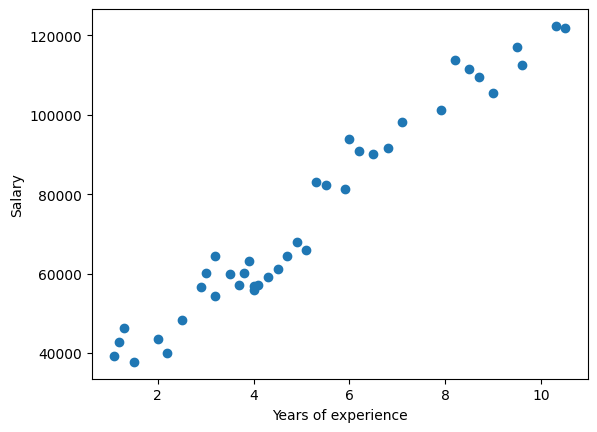

In [13]:
# STEP 6: Plot it. Do you see a pattern?
plt.scatter(df["exp"], df["salary"])
plt.xlabel("Years of experience")
plt.ylabel("Salary")
plt.show()

In [15]:
# STEP 7: Split into inputs (X) and the answer we want to predict (y)
X = df[["exp"]]        # double brackets: X must be a table
y = df["salary"]       # single brackets: y is one column

In [16]:
# STEP 8: Split into training data (80%) and test data (20%)
# The model learns from the training data. We check it on the test data it has never seen.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 32
Test rows: 8


In [17]:
# STEP 9: Create the model and train it
from sklearn.linear_model import LinearRegression

model = LinearRegression()      # an empty model
model.fit(X_train, y_train)     # training: find the best line
print("Trained!")

Trained!


In [18]:
# STEP 10: What did the model learn? (salary = slope * years + intercept)
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 9408.03127250658
Intercept: 26716.250176145535


In [19]:
# STEP 11: Predict salaries for the test data
y_pred = model.predict(X_test)
print(y_pred)

[ 69052.39090243  64348.37526617  64348.37526617  83164.43781119
  45532.31272116  61525.96588442 117033.35039221  85046.04406569]


In [20]:
# STEP 12: Compare predictions with real salaries
results = pd.DataFrame({"experience": X_test["exp"], "actual": y_test, "predicted": y_pred})
results["error"] = results["actual"] - results["predicted"]
results

,experience,actual,predicted,error
19,4.5,61111,69052.390902,-7941.390902
16,4.0,56957,64348.375266,-7391.375266
15,4.0,55794,64348.375266,-8554.375266
26,6.0,93940,83164.437811,10775.562189
4,2.0,43525,45532.312721,-2007.312721
12,3.7,57189,61525.965884,-4336.965884
37,9.6,112635,117033.350392,-4398.350392
27,6.2,91000,85046.044066,5953.955934


In [21]:
# STEP 13: Measure how wrong the model is
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mse = mean_squared_error(y_test, y_pred)    # average of squared errors
rmse = np.sqrt(mse)                         # back in salary units
mae = mean_absolute_error(y_test, y_pred)   # average absolute error
r2 = r2_score(y_test, y_pred)               # 1 = perfect

print("MSE :", mse)
print("RMSE:", rmse)
print("MAE :", mae)
print("R2  :", r2)

MSE : 48077731.16919359
RMSE: 6933.810724932834
MAE : 6419.911069460598
R2  : 0.9068577573647874


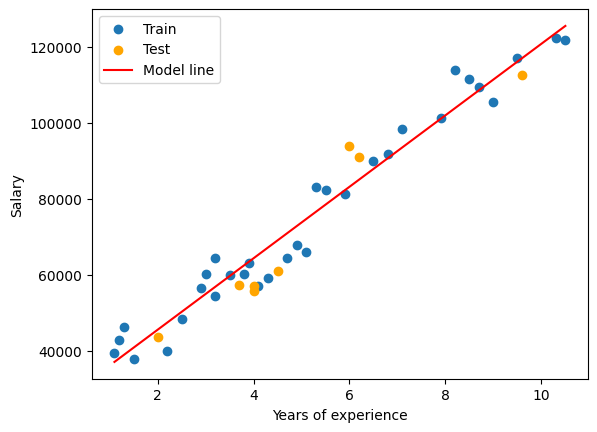

In [22]:
# STEP 14: Plot the line the model learned
plt.scatter(X_train, y_train, label="Train")
plt.scatter(X_test, y_test, color="orange", label="Test")
plt.plot(X, model.predict(X), color="red", label="Model line")
plt.xlabel("Years of experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

In [ ]:
# STEP 15: Predict for any experience you like!
my_years = pd.DataFrame({"exp": [3, 6, 10]})
print(model.predict(my_years))

In [ ]:
# STEP 16: Your turn. Try these:
# a) Change test_size to 0.3 in Step 8. What happens to the MSE?
# b) Change random_state to 1 in Step 8. Does the MSE change? Why?
# c) Predict the salary for 30 years of experience. Do you trust it?